# Milestone 2: Model Tambahan dan Eksperimen Perbandingan (Churn Telco)

Bagian ini melanjutkan `churn_analysis.ipynb` (Milestone 1). Semua model dievaluasi dengan **protokol yang sama** dengan CV utama Milestone 1 (bagian 6): data 7.043 pelanggan, 21 fitur (termasuk `TenureGroup` dan `TotalServices`), preprocessing di dalam `Pipeline`, `RepeatedStratifiedKFold` 5-fold x 3 pengulangan (`random_state=42`), dan metrik Accuracy, Precision, Recall, F1, PR-AUC pada kelas churn.

**Cara memakai (pilih salah satu):**
1. Jalankan notebook ini apa adanya (Runtime > Run all). Data diunduh otomatis bila belum ada.
2. Salin seluruh sel ini ke bagian akhir `churn_analysis.ipynb`. Sel data akan memakai variabel `telco` yang sudah bersih dari notebook itu.

**Pembagian pengisian:** Radhit mengisi sel *Model tambahan 1*, Yohanes mengisi sel *Model tambahan 2*. Sel lain tidak perlu diubah, supaya protokolnya tetap sama untuk semua model.

## M2.0 Persiapan: data dan fungsi evaluasi bersama

In [1]:
import json
import os
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import (
    GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Konstanta protokol: JANGAN diubah per model.
SEED = 42
N_SPLITS = 5
N_REPEATS = 3
SERVICE_COLS = [
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
]
SCORING = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1': make_scorer(f1_score, zero_division=0),
    'PR-AUC': 'average_precision',   # memakai predict_proba atau decision_function
}
print('Protokol: RepeatedStratifiedKFold', N_SPLITS, 'fold x', N_REPEATS, 'pengulangan, random_state =', SEED)

Protokol: RepeatedStratifiedKFold 5 fold x 3 pengulangan, random_state = 42


In [2]:
# Data: pakai `telco` dari notebook Milestone 1 bila sudah ada (sudah bersih).
# Kalau notebook ini dijalankan sendiri, data diunduh dan dibersihkan dengan langkah yang sama (bagian 1 Milestone 1).
if 'telco' not in globals():
    folder = Path('datasets'); folder.mkdir(parents=True, exist_ok=True)
    zip_path = folder / 'Churn_Customer_telco.zip'
    csv_path = folder / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
    if not zip_path.is_file() and not csv_path.is_file():
        urllib.request.urlretrieve(
            'https://github.com/carlos1739/analisis_telco/raw/master/data/Churn_Customer_telco.zip', zip_path)
    if not csv_path.is_file():
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(folder)

    telco = pd.read_csv(csv_path)
    telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'].astype(str).str.strip(), errors='coerce')
    telco.loc[telco['TotalCharges'].isnull(), 'TotalCharges'] = 0   # pelanggan baru, belum ditagih
    telco = telco.drop(columns=['customerID'], errors='ignore')
    for col in telco.select_dtypes(exclude='number').columns:
        if col != 'SeniorCitizen':
            telco[col] = telco[col].str.strip()
    telco['MultipleLines'] = telco['MultipleLines'].replace('No phone service', 'No')
    for col in ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']:
        telco[col] = telco[col].replace('No internet service', 'No')
    telco['SeniorCitizen'] = telco['SeniorCitizen'].astype(object)

# Feature engineering yang sama dengan CV utama Milestone 1 (sel 89)
data_eval = telco.copy()
data_eval['TenureGroup'] = pd.cut(
    data_eval['tenure'], bins=[-1, 12, 24, 48, 72],
    labels=['0-12 bulan', '13-24 bulan', '25-48 bulan', '49-72 bulan'], include_lowest=True)
data_eval['TotalServices'] = data_eval[SERVICE_COLS].eq('Yes').sum(axis=1)
X_eval = data_eval.drop(columns='Churn')
y_eval = data_eval['Churn'].map({'No': 0, 'Yes': 1}).astype(int)

numeric_cols = X_eval.select_dtypes(include='number').columns.tolist()
categorical_cols = X_eval.select_dtypes(exclude='number').columns.tolist()
print(f'Observasi: {len(X_eval):,} | Fitur: {X_eval.shape[1]} | Numerik: {len(numeric_cols)} | '
      f'Kategorikal: {len(categorical_cols)} | Proporsi churn: {y_eval.mean():.3f}')

Observasi: 7,043 | Fitur: 21 | Numerik: 4 | Kategorikal: 17 | Proporsi churn: 0.265


In [3]:
def buat_preprocessor():
    # Di dalam Pipeline, jadi dipelajari ulang dari data training tiap fold (tanpa kebocoran data).
    return ColumnTransformer(
        transformers=[
            ('numeric', StandardScaler(), numeric_cols),
            ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ],
        remainder='drop', sparse_threshold=0,
    )

def buat_cv():
    return RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

def _ringkas(nama, skor):
    baris = {'Model': nama}
    for metrik in SCORING:
        baris[f'{metrik} (mean)'] = skor[f'test_{metrik}'].mean()
        baris[f'{metrik} (std)'] = skor[f'test_{metrik}'].std()
    return baris

def evaluasi_model(nama, estimator):
    # Evaluasi satu model dengan protokol bersama. Mengembalikan (ringkasan, skor_per_fold).
    pipe = Pipeline([('preprocess', buat_preprocessor()), ('model', estimator)])
    skor = cross_validate(pipe, X_eval, y_eval, cv=buat_cv(), scoring=SCORING, n_jobs=1, error_score='raise')
    return _ringkas(nama, skor), skor

def evaluasi_model_tuning(nama, estimator, param_grid, inner_splits=3):
    # Evaluasi DENGAN tuning secara nested: GridSearchCV dijalankan di dalam data training tiap fold luar,
    # sehingga tuning tidak memakai data uji. Nama parameter diawali 'model__', contoh {'model__C': [0.1, 1]}.
    pipe = Pipeline([('preprocess', buat_preprocessor()), ('model', estimator)])
    inner = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=SEED)
    grid = GridSearchCV(pipe, param_grid, cv=inner, scoring='average_precision', n_jobs=1)
    skor = cross_validate(grid, X_eval, y_eval, cv=buat_cv(), scoring=SCORING,
                          n_jobs=1, error_score='raise', return_estimator=True)
    terpilih = [est.best_params_ for est in skor['estimator']]
    return _ringkas(nama, skor), skor, terpilih

def bandingkan_berpasangan(nama_a, nama_b, metrik='PR-AUC'):
    # Selisih metrik per fold (fold sama persis, jadi bisa dipasangkan). Gambaran deskriptif, bukan uji signifikansi:
    # fold pada repeated CV saling berkaitan.
    selisih = skor_fold[nama_a][f'test_{metrik}'] - skor_fold[nama_b][f'test_{metrik}']
    return {'metrik': metrik, 'A': nama_a, 'B': nama_b,
            'selisih rata-rata (A-B)': round(float(selisih.mean()), 4),
            'SD selisih': round(float(selisih.std()), 4),
            'fold A > B': int((selisih > 0).sum()), 'fold A < B': int((selisih < 0).sum()),
            'jumlah fold': int(len(selisih))}

# Penampung hasil semua model (dipakai tabel perbandingan dan penyimpanan konfigurasi)
hasil_baris, skor_fold, konfigurasi, tuning_terpilih = [], {}, {}, {}

def jalankan_varian(varian):
    # varian: {nama: (estimator, param_grid atau None)}. param_grid=None berarti tanpa tuning.
    for nama, (estimator, grid) in varian.items():
        if grid:
            baris, skor, terpilih = evaluasi_model_tuning(nama, estimator, grid)
            tuning_terpilih[nama] = terpilih
            konfigurasi[nama] = {**estimator.get_params(), '_grid_tuning': grid}
        else:
            baris, skor = evaluasi_model(nama, estimator)
            konfigurasi[nama] = estimator.get_params()
        hasil_baris.append(baris); skor_fold[nama] = skor
        print(f"{nama}: PR-AUC {baris['PR-AUC (mean)']:.3f} +/- {baris['PR-AUC (std)']:.3f} | "
              f"Recall {baris['Recall (mean)']:.3f} | Precision {baris['Precision (mean)']:.3f} | F1 {baris['F1 (mean)']:.3f}")

## M2.1 Baseline dan kandidat Milestone 1 (dijalankan ulang)

Konfigurasi di bawah **sama persis** dengan sel 89 `churn_analysis.ipynb` dan tidak boleh diubah. Dijalankan ulang di sini agar perbandingan memakai pipeline dan fold yang identik dan hasilnya dapat ditelusuri.

In [4]:
kandidat_m1 = {
    'Baseline mayoritas': (DummyClassifier(strategy='most_frequent'), None),
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), None),
    'KNN': (KNeighborsClassifier(n_neighbors=11), None),
    'Decision Tree': (DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=42), None),
    'Random Forest': (RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=10,
        class_weight='balanced_subsample', random_state=42, n_jobs=1), None),
    'HistGradientBoosting': (HistGradientBoostingClassifier(
        max_iter=150, learning_rate=0.1, max_leaf_nodes=15,
        min_samples_leaf=30, l2_regularization=1.0, random_state=42), None),
}
jalankan_varian(kandidat_m1)

Baseline mayoritas: PR-AUC 0.265 +/- 0.000 | Recall 0.000 | Precision 0.000 | F1 0.000
Logistic Regression: PR-AUC 0.660 +/- 0.018 | Recall 0.531 | Precision 0.665 | F1 0.590
KNN: PR-AUC 0.576 +/- 0.015 | Recall 0.536 | Precision 0.587 | F1 0.560
Decision Tree: PR-AUC 0.613 +/- 0.019 | Recall 0.798 | Precision 0.506 | F1 0.619
Random Forest: PR-AUC 0.662 +/- 0.019 | Recall 0.763 | Precision 0.541 | F1 0.633
HistGradientBoosting: PR-AUC 0.655 +/- 0.019 | Recall 0.529 | Precision 0.651 | F1 0.583


### Cek reproduksi

Hasil di atas harus sama dengan Tabel CV utama Milestone 1. Toleransinya 0,005: Logistic Regression, KNN, Decision Tree, dan baseline biasanya identik sampai pembulatan, sedangkan Random Forest dan HistGradientBoosting bisa bergeser sekitar 0,001 sampai 0,003 antar-versi scikit-learn. Selisih lebih besar dari itu berarti ada yang berbeda (data, fitur, atau konfigurasi); jangan lanjut ke model tambahan sebelum penyebabnya ketemu.

In [5]:
# Acuan: tabel CV utama Milestone 1 (bagian 6.1): Accuracy, Precision, Recall, F1, PR-AUC (rata-rata)
acuan_m1 = {
    'Baseline mayoritas':   (0.735, 0.000, 0.000, 0.000, 0.265),
    'Logistic Regression':  (0.804, 0.665, 0.531, 0.590, 0.660),
    'KNN':                  (0.777, 0.587, 0.536, 0.560, 0.576),
    'Decision Tree':        (0.739, 0.506, 0.798, 0.619, 0.613),
    'Random Forest':        (0.765, 0.541, 0.763, 0.633, 0.662),
    'HistGradientBoosting': (0.800, 0.651, 0.529, 0.583, 0.655),
}
df_tmp = pd.DataFrame(hasil_baris).set_index('Model')
semua_cocok = True
for nama, ref in acuan_m1.items():
    now = [df_tmp.loc[nama, f'{m} (mean)'] for m in ['Accuracy', 'Precision', 'Recall', 'F1', 'PR-AUC']]
    selisih = max(abs(a - b) for a, b in zip(now, ref))
    ok = selisih <= 0.005
    semua_cocok &= ok
    print(f"{nama:22s} selisih maks = {selisih:.4f}  {'COCOK' if ok else 'BEDA'}")
print('\nReproduksi Milestone 1:', 'BERHASIL' if semua_cocok else 'ADA YANG BEDA, periksa sebelum lanjut')

Baseline mayoritas     selisih maks = 0.0004  COCOK
Logistic Regression    selisih maks = 0.0004  COCOK
KNN                    selisih maks = 0.0005  COCOK
Decision Tree          selisih maks = 0.0005  COCOK
Random Forest          selisih maks = 0.0004  COCOK
HistGradientBoosting   selisih maks = 0.0005  COCOK

Reproduksi Milestone 1: BERHASIL


## M2.2 Model tambahan 1 (diisi Radhit)

Isi `varian_model_1` di bawah. Format: `{'Nama varian': (estimator, param_grid atau None)}`.
- `param_grid=None` berarti tanpa tuning; isi dict untuk tuning nested, dengan awalan `model__` (misalnya `{'model__C': [0.01, 0.1, 1, 10]}`).
- Jika algoritmanya punya `class_weight`, buat **dua varian** (dengan dan tanpa `class_weight='balanced'`) supaya pengaruhnya terlihat dan perbandingan adil.
- Catat alasan pemilihan model dan parameter di laporan (Bagian 3 dan 5).

In [6]:
# === RADHIT: isi di sini ===
# Contoh bentuk (hapus tanda # dan sesuaikan; JANGAN dipakai mentah-mentah tanpa alasan pemilihan di laporan):
#
# from sklearn.svm import LinearSVC
# varian_model_1 = {
#     'SVM linear':           (LinearSVC(max_iter=5000, random_state=42), {'model__C': [0.01, 0.1, 1, 10]}),
#     'SVM linear balanced':  (LinearSVC(max_iter=5000, class_weight='balanced', random_state=42), {'model__C': [0.01, 0.1, 1, 10]}),
# }

varian_model_1 = {}
jalankan_varian(varian_model_1)

## M2.3 Model tambahan 2 (diisi Yohanes)

Aturan pengisiannya sama dengan M2.2. Naive Bayes tidak punya `class_weight`, jadi cukup satu varian per jenis (misalnya `BernoulliNB`, `CategoricalNB`, atau `GaussianNB`); alasan memilih varian itu dicatat di laporan.

In [7]:
# === YOHANES: isi di sini ===
# Contoh bentuk (hapus tanda # dan sesuaikan):
#
# from sklearn.naive_bayes import BernoulliNB
# varian_model_2 = {
#     'Naive Bayes (Bernoulli)': (BernoulliNB(), {'model__alpha': [0.1, 0.5, 1.0, 2.0]}),
# }

varian_model_2 = {}
jalankan_varian(varian_model_2)

## M2.4 Tabel dan visualisasi perbandingan

In [8]:
tabel = pd.DataFrame(hasil_baris).set_index('Model').sort_values('PR-AUC (mean)', ascending=False)
display(tabel.round(3))

,Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),F1 (mean),F1 (std),PR-AUC (mean),PR-AUC (std)
Model,,,,,,,,,,
Random Forest,0.765,0.009,0.541,0.013,0.763,0.028,0.633,0.015,0.662,0.019
Logistic Regression,0.804,0.007,0.665,0.018,0.531,0.020,0.590,0.016,0.660,0.018
HistGradientBoosting,0.800,0.008,0.651,0.019,0.529,0.029,0.583,0.021,0.655,0.019
Decision Tree,0.739,0.013,0.506,0.016,0.798,0.031,0.619,0.012,0.613,0.019
KNN,0.777,0.012,0.587,0.025,0.536,0.029,0.560,0.024,0.576,0.015
Baseline mayoritas,0.735,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.265,0.000


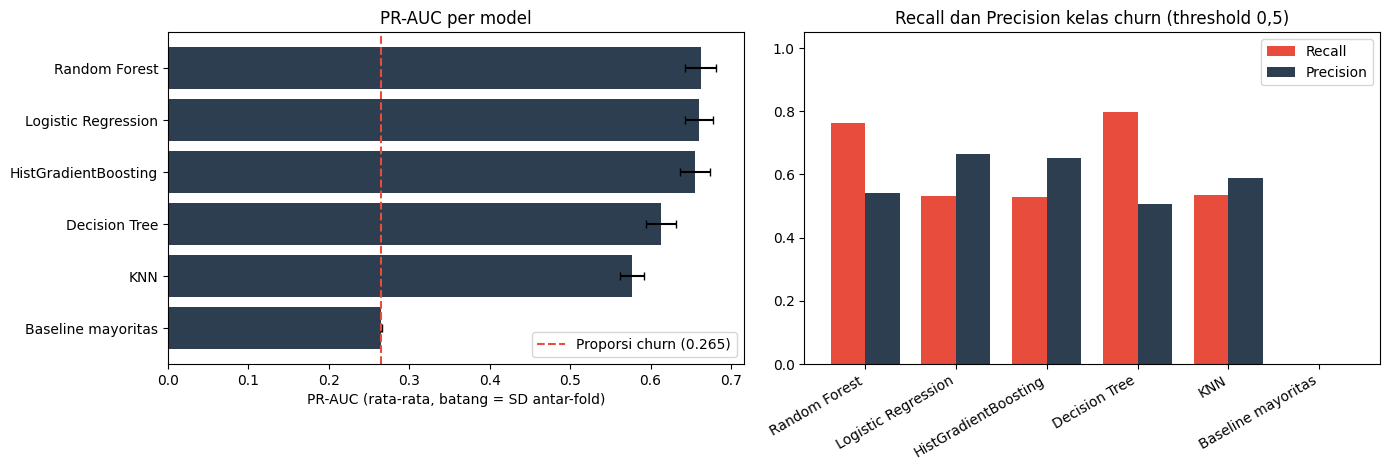

In [9]:
# Visualisasi: PR-AUC (dengan SD antar-fold) dan Recall vs Precision pada threshold 0,5
nama = list(tabel.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.barh(nama, tabel['PR-AUC (mean)'], xerr=tabel['PR-AUC (std)'], color='#2C3E50', capsize=3)
ax.axvline(y_eval.mean(), ls='--', color='#E74C3C', label=f'Proporsi churn ({y_eval.mean():.3f})')
ax.set_xlabel('PR-AUC (rata-rata, batang = SD antar-fold)'); ax.set_title('PR-AUC per model'); ax.invert_yaxis(); ax.legend()

ax = axes[1]
x = np.arange(len(nama)); w = 0.38
ax.bar(x - w/2, tabel['Recall (mean)'], w, label='Recall', color='#E74C3C')
ax.bar(x + w/2, tabel['Precision (mean)'], w, label='Precision', color='#2C3E50')
ax.set_xticks(x); ax.set_xticklabels(nama, rotation=30, ha='right'); ax.set_ylim(0, 1.05)
ax.set_title('Recall dan Precision kelas churn (threshold 0,5)'); ax.legend()
plt.tight_layout(); plt.show()

In [10]:
# Selisih per fold: model tambahan vs Logistic Regression dan vs Random Forest (hanya bila model tambahan sudah diisi)
tambahan = [n for n in skor_fold if n not in kandidat_m1]
pembanding = ['Logistic Regression', 'Random Forest']
rows = [bandingkan_berpasangan(a, b) for a in tambahan for b in pembanding]
if rows:
    display(pd.DataFrame(rows))
else:
    print('Belum ada model tambahan. Isi sel M2.2 dan M2.3 terlebih dahulu.')

# Parameter terpilih tuning di tiap fold luar (untuk dibahas stabilitasnya)
for n, p in tuning_terpilih.items():
    print(n, '->', pd.Series([str(d) for d in p]).value_counts().to_dict())

Belum ada model tambahan. Isi sel M2.2 dan M2.3 terlebih dahulu.


## M2.5 Simpan hasil dan konfigurasi (artefak repo)

Menyimpan tabel perbandingan dan seluruh konfigurasi eksperimen ke folder `results/` untuk dokumentasi dan keterlacakan.

In [11]:
os.makedirs('results', exist_ok=True)
tabel.round(4).to_csv('results/perbandingan_model_milestone2.csv')

catatan = {
    'protokol': {
        'cv': f'RepeatedStratifiedKFold {N_SPLITS}-fold x {N_REPEATS} pengulangan',
        'random_state': SEED,
        'preprocessing': 'StandardScaler (numerik) + OneHotEncoder (kategorikal) di dalam Pipeline',
        'metrik': list(SCORING), 'kelas_positif': 'Churn = 1',
        'tuning': "nested: GridSearchCV 3-fold (skor average_precision) di dalam tiap fold luar",
    },
    'model': {n: {k: repr(v) for k, v in cfg.items()} for n, cfg in konfigurasi.items()},
    'parameter_terpilih_tuning': {n: [str(d) for d in p] for n, p in tuning_terpilih.items()},
}
with open('results/konfigurasi_eksperimen.json', 'w', encoding='utf-8') as f:
    json.dump(catatan, f, indent=2, ensure_ascii=False)
print('Tersimpan: results/perbandingan_model_milestone2.csv dan results/konfigurasi_eksperimen.json')

Tersimpan: results/perbandingan_model_milestone2.csv dan results/konfigurasi_eksperimen.json


### Catatan untuk analisis (Bagian 6 sampai 8 laporan)

- Kandidat Milestone 1 **tidak di-tuning**, sedangkan model tambahan di-tuning secara nested. Sebutkan perbedaan ini saat menafsirkan hasil.
- Selisih PR-AUC yang jauh lebih kecil dari SD antar-fold (sekitar 0,02) tidak boleh dibaca sebagai keunggulan. SD di sini bukan interval kepercayaan karena fold pada repeated CV saling berkaitan.
- Recall dan Precision dihitung pada threshold 0,5. Perbedaan Recall antar-model dipengaruhi `class_weight`, yang di Milestone 1 hanya dipakai pada Decision Tree dan Random Forest.
- Hasil yang tidak lebih baik dari baseline atau kandidat sebelumnya tetap dilaporkan apa adanya.